# 01 · Representaciones tiempo-frecuencia

**Fase 0.** Comparar STFT, espectrograma mel y CQT en un fragmento de rock y uno de música de cámara, para ver por qué la música clásica es difícil de transcribir y qué aporta separar.

Usa grabaciones reales que descarga `npm run local:real-audio` en `data/real/` (no se suben al repo):

- **MUSDB18, extractos de 7 s** ([Zenodo](https://zenodo.org/records/3270814), CC BY 4.0): 144 fragmentos reales de rock y pop **con sus stems verdaderos** (voz, batería, bajo, resto).
- **TRIOS** ([Zenodo](https://zenodo.org/records/6797837), CC BY-NC-SA 2.0 UK): cinco tríos (Brahms, Lussier, Mozart, Schubert y *Take Five*) grabados instrumento por instrumento, **con el MIDI alineado**.

No hay grabaciones abiertas de orquesta completa con la verdad nota por nota (URMP y Bach10 piden registro); TRIOS es lo más cercano: instrumentos de orquesta reales, en grupos de tres.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")  # repo root: src.*

import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

REAL = Path("../data/real")  # npm run local:real-audio
OUTPUTS = Path("../outputs")
SR = 22050

In [2]:
# (archivo, segundo de inicio). 7 s porque los extractos de MUSDB duran eso.
CLIPS = {
    "rock": (REAL / "musdb7/test/Louis Cressy Band - Good Time/mixture.wav", 0.0),
    "trío (Schubert)": (REAL / "trios/schubert/mix.wav", 5.6),
}
DUR = 7

audio = {name: librosa.load(path, sr=SR, mono=True, offset=start, duration=DUR)[0]
         for name, (path, start) in CLIPS.items()}
for name, y in audio.items():
    print(name, f"{len(y) / SR:.1f} s")
    display(Audio(y, rate=SR))

rock 6.8 s


trío (Schubert) 7.0 s


## STFT

$X(f,\tau)=\text{STFT}\{x\}$, con resolución en frecuencia lineal: $\Delta f = f_s / N_{FFT}$. En graves (bajo, contrabajo, trombón) varias notas caen en el mismo bin.

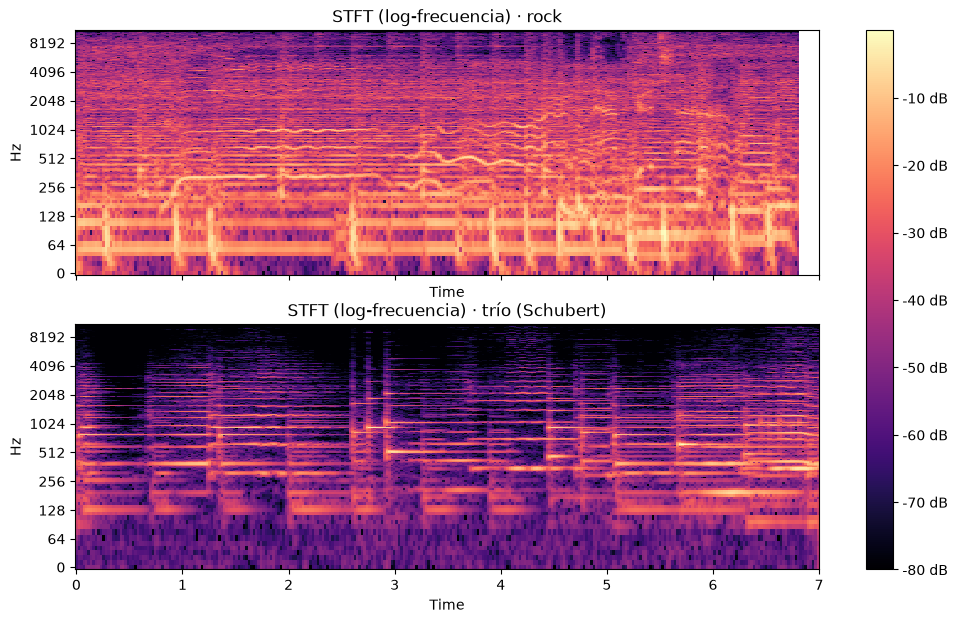

In [3]:
N_FFT, HOP = 2048, 512

fig, axes = plt.subplots(len(audio), 1, figsize=(12, 7), sharex=True)
for ax, (name, y) in zip(axes, audio.items()):
    S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP)), ref=np.max)
    img = librosa.display.specshow(S_db, sr=SR, hop_length=HOP, x_axis="time", y_axis="log", ax=ax)
    ax.set_title(f"STFT (log-frecuencia) · {name}")
fig.colorbar(img, ax=axes, format="%+2.0f dB")
plt.show()

## Espectrograma mel

Escala perceptual: más resolución en graves y medios. Es la entrada típica de los modelos de separación y de transcripción.

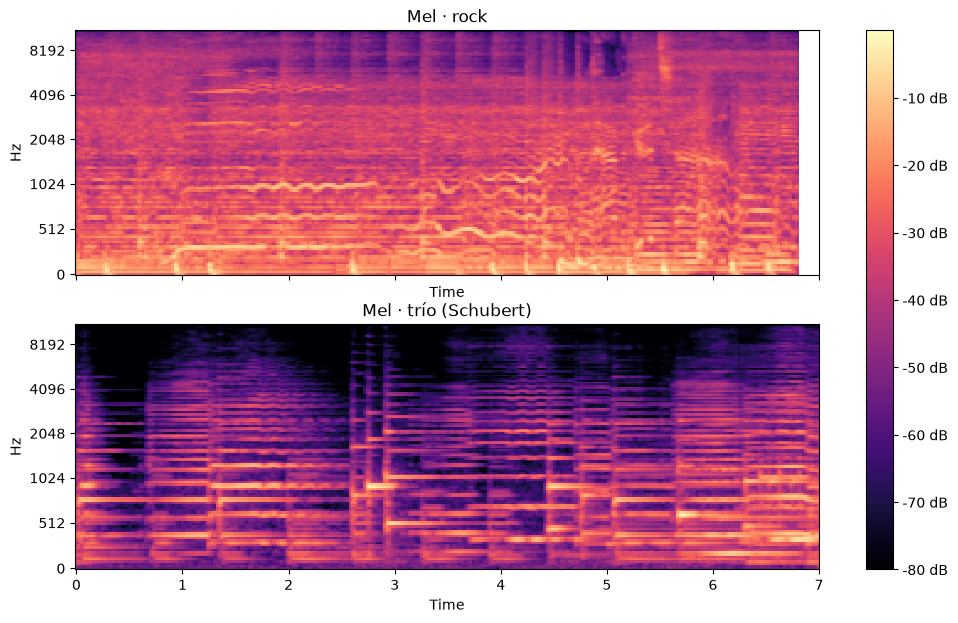

In [4]:
fig, axes = plt.subplots(len(audio), 1, figsize=(12, 7), sharex=True)
for ax, (name, y) in zip(axes, audio.items()):
    M_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=128), ref=np.max)
    img = librosa.display.specshow(M_db, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(f"Mel · {name}")
fig.colorbar(img, ax=axes, format="%+2.0f dB")
plt.show()

## CQT

Bins espaciados en semitonos ($f_k = f_{min} \cdot 2^{k/B}$): cada fila corresponde a una nota. Es la representación más cercana a un piano-roll, y la que usa Basic Pitch internamente (CQT armónica). En el trío se superpone el MIDI de la partitura (puntos blancos) para ver qué líneas son notas y cuáles armónicos.

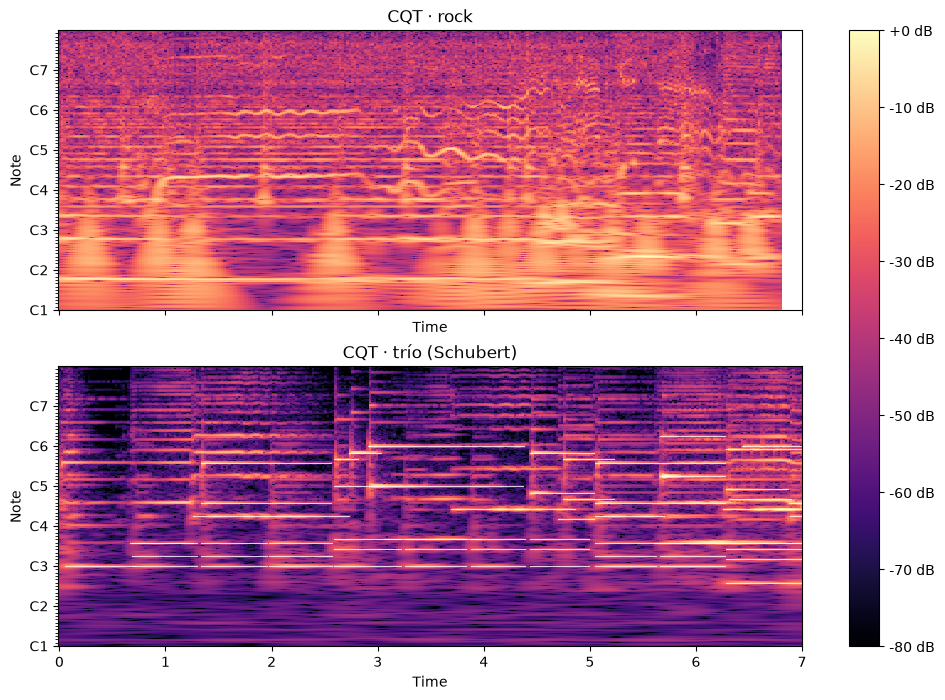

In [5]:
import pretty_midi

BINS_PER_OCTAVE = 36  # 3 bins por semitono
FMIN = librosa.note_to_hz("C1")

trio_path, trio_start = CLIPS["trío (Schubert)"]
score_notes = [(n.start - trio_start, n.end - trio_start, n.pitch)
               for midi in sorted(trio_path.parent.glob("*.mid"))
               for inst in pretty_midi.PrettyMIDI(str(midi)).instruments for n in inst.notes
               if trio_start <= n.start < trio_start + DUR]

fig, axes = plt.subplots(len(audio), 1, figsize=(12, 8), sharex=True)
for ax, (name, y) in zip(axes, audio.items()):
    C_db = librosa.amplitude_to_db(
        np.abs(librosa.cqt(y, sr=SR, hop_length=HOP, fmin=FMIN, n_bins=7 * BINS_PER_OCTAVE, bins_per_octave=BINS_PER_OCTAVE)),
        ref=np.max,
    )
    img = librosa.display.specshow(C_db, sr=SR, hop_length=HOP, x_axis="time", y_axis="cqt_note",
                                   fmin=FMIN, bins_per_octave=BINS_PER_OCTAVE, ax=ax)
    if name.startswith("trío"):
        for start, end, pitch in score_notes:
            ax.plot([start, min(end, DUR)], [librosa.midi_to_hz(pitch)] * 2, color="white", lw=0.8, alpha=0.8)
    ax.set_title(f"CQT · {name}")
fig.colorbar(img, ax=axes, format="%+2.0f dB")
plt.show()

## Cromagrama y densidad espectral

Dos medidas rápidas de "cuánta polifonía" hay: el cromagrama (energía por clase de altura) y la planitud espectral (cerca de 1 = ruido, cerca de 0 = tonal).

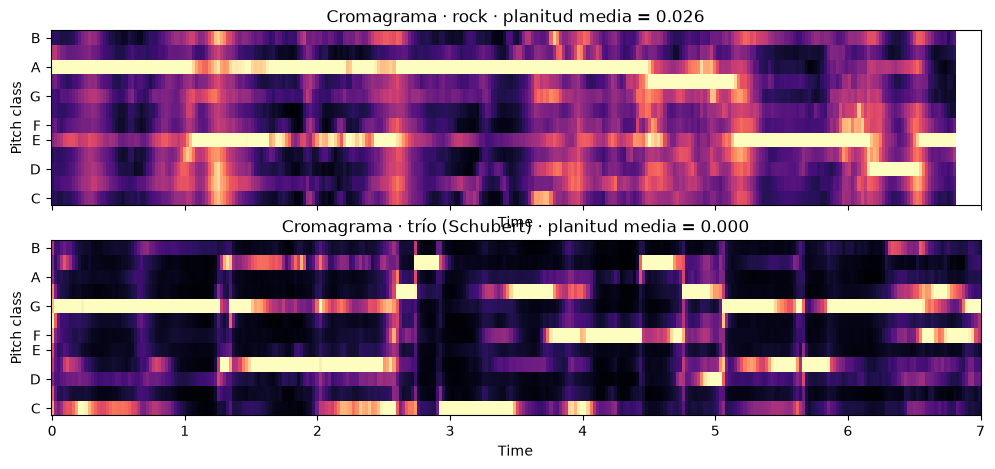

In [6]:
fig, axes = plt.subplots(len(audio), 1, figsize=(12, 5), sharex=True)
for ax, (name, y) in zip(axes, audio.items()):
    chroma = librosa.feature.chroma_cqt(y=y, sr=SR, hop_length=HOP)
    librosa.display.specshow(chroma, sr=SR, hop_length=HOP, x_axis="time", y_axis="chroma", ax=ax)
    flat = librosa.feature.spectral_flatness(y=y, hop_length=HOP).mean()
    ax.set_title(f"Cromagrama · {name} · planitud media = {flat:.3f}")
plt.show()

## Planitud en más canciones

Una canción no basta para decir algo del modo automático (`routing.py`, que usa la energía percusiva). Se mide la planitud media y la fracción de energía percusiva (HPSS) en las 50 canciones de prueba de MUSDB y en los 5 tríos.

In [7]:
from src.pipeline import routing

rows = []
for path in sorted((REAL / "musdb7/test").glob("*/mixture.wav")):
    rows.append(("MUSDB", path.parent.name, path))
for path in sorted((REAL / "trios").glob("*/mix.wav")):
    rows.append(("TRIOS", path.parent.name, path))

stats = []
for source, name, path in rows:
    y, _ = librosa.load(path, sr=SR, mono=True, duration=DUR, offset=0 if source == "MUSDB" else 5)
    flat = float(librosa.feature.spectral_flatness(y=y).mean())
    decision = routing.classify(y, SR)
    stats.append((source, name, flat, decision.features["percussive_share"], decision.probability_rock))

for source in ("MUSDB", "TRIOS"):
    sel = [s for s in stats if s[0] == source]
    flats = np.array([s[2] for s in sel]); perc = np.array([s[3] for s in sel]); prob = np.array([s[4] for s in sel])
    print(f"{source}: {len(sel)} clips · planitud mediana={np.median(flats):.4f} · energía percusiva mediana={np.median(perc):.2f}"
          f" · p(rock)≥0.5 en {np.mean(prob >= 0.5):.0%}")
print()
for s in stats:
    if s[0] == "TRIOS":
        print(f"  {s[1]:10s} planitud={s[2]:.4f}  percusiva={s[3]:.2f}  p(rock)={s[4]:.2f}")

MUSDB: 50 clips · planitud mediana=0.0178 · energía percusiva mediana=0.26 · p(rock)≥0.5 en 100%
TRIOS: 5 clips · planitud mediana=0.0003 · energía percusiva mediana=0.06 · p(rock)≥0.5 en 100%

  brahms     planitud=0.0003  percusiva=0.02  p(rock)=0.98
  lussier    planitud=0.0001  percusiva=0.06  p(rock)=0.99
  mozart     planitud=0.0001  percusiva=0.05  p(rock)=0.98
  schubert   planitud=0.0004  percusiva=0.07  p(rock)=0.99
  take_five  planitud=0.0384  percusiva=0.43  p(rock)=0.99


## Hallazgos

Ejecutado el 25 oct 2026 con grabaciones reales: un extracto de rock de MUSDB18 (*Louis Cressy Band – Good Time*) y el trío de Schubert de TRIOS (violín, violonchelo y piano).

- **¿En cuál se distinguen mejor las notas en la CQT?** En el trío. Cada nota es una línea horizontal con sus armónicos encima, y el MIDI de la partitura (en blanco) cae justo sobre las fundamentales: la alineación de TRIOS es buena. En el rock todo es denso:
  - la batería es una niebla de banda ancha;
  - la voz se ve como líneas onduladas (vibrato) entre Do4 y Do6;
  - solo el bajo (La1) se lee limpio, abajo.
- **Registro grave.** Con la STFT (`n_fft` 2048 a 22 050 Hz) cada bin mide 10,8 Hz, y por debajo de ~100 Hz dos semitonos caen en el mismo bin. En el rock, el bombo se monta sobre la fundamental del bajo. Por eso el bajo se transcribe desde su stem (en el notebook 03, separar casi triplica el F1 del bajo).
- **Armónicos.** Los instrumentos reales tienen muchos más armónicos que la demo sintética: en el trío se ven 5–8 líneas por nota. El 2.º armónico (la octava) es el que más confunde a un transcriptor.
- **Planitud espectral**, medida en las 50 canciones de MUSDB y los 5 tríos:
  - la mediana es 0,018 en el rock y 0,0003 en los tríos clásicos, unas 60 veces menos;
  - *Take Five*, el trío con batería, da 0,038, como el rock.

  La percusión es lo que separa los dos mundos.
- **Bug del modo automático (`routing.py`).** Clasifica los 5 tríos como rock, con `p(rock)` ≈ 0,98, aunque su energía percusiva es mínima (0,02–0,07 contra una mediana de 0,26 en el rock).
  - El culpable es la tasa de golpes graves: en los tríos sale **más alta** (8–9 por segundo) que en el rock (mediana 6), porque el detector cuenta como golpe cada nota grave del piano o del violonchelo.
  - Con esos pesos, el modo automático elige rock siempre.
  - La energía percusiva sola casi separa los dos grupos: el tema de rock más suave da 0,061 y el trío más percusivo 0,068. Recomendación: quitar la tasa de golpes, usar solo la energía percusiva con un umbral cercano a 0,09 y calibrarlo con más datos, o pasar al clasificador del plan (CLAP o PANNs).